I held the TRIK robot in my hands so that both wheels were in the air and ran `motor_identification.qrs` twice: once on M4 (left wheel, encoder E4) and once on a copy set to M3 (right wheel, encoder E3), about 2 minutes each. The program first logs 3 s with the motor off to check for encoder drift, then goes through every PWM level from −100 % to +100 % in 5 % steps (0 is skipped): 2 s with the motor on, then 1 s off so the wheel coasts. Every line of the file is `angle,time,pwm` (encoder angle in degrees, robot time in ms, the PWM being applied), so one file can later be split into the 40 steps. The battery showed 12.1 V both before and after the runs, so I take U_battery = 12.1 V for both motors.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize             # curve_fit: fits the model to the data
from scipy.integrate import odeint     # ODE solver for the simulation in section 4

DATA = "motor_data"                        # folder with the robot files
MOTORS = {"M4": "left", "M3": "right"}     # motor -> wheel it drives
LINEAR_FROM = 20                           # |PWM| >= 20 % is the linear part of w_ss(PWM)


def load(motor):
    # read steps5_M4.txt / steps5_M3.txt -> three arrays: angle [deg], time [ms], pwm [%]
    angle, t, pwm = np.loadtxt(os.path.join(DATA, f"steps5_{motor}.txt"), delimiter=",", unpack=True)
    return angle, t, pwm


battery = {}                               # motor -> mean of the voltage before and after the run
for line in open(os.path.join(DATA, "battery.txt")):    # lines like "steps5_M4.txt,12.1,12.1"
    parts = line.strip().split(",")
    if len(parts) == 3 and parts[0].startswith("steps5_") and parts[1] and parts[2]:
        battery[parts[0][7:9]] = (float(parts[1]) + float(parts[2])) / 2

for m in MOTORS:                           # quick check of each file
    angle, t, pwm = load(m)
    dt = np.diff(t)                        # real time between samples (the Timer asks for 5 ms)
    print(f"{m} ({MOTORS[m]}): {len(t)} samples, {(t[-1] - t[0]) / 1000:.1f} s, "
          f"sampling {dt.mean():.1f} ms (min {dt.min():.0f}, max {dt.max():.0f}), battery {battery[m]:.2f} V")

M4 (left): 3608 samples, 123.5 s, sampling 34.2 ms (min 28, max 80), battery 12.10 V
M3 (right): 3672 samples, 123.6 s, sampling 33.7 ms (min 29, max 93), battery 12.10 V


$\omega_{ss}$ is the steady-state angular speed the wheel settles at for a given voltage, in rad/s. $T_m$ is the mechanical time constant in seconds: the time after which the speed reaches $1 - e^{-1} \approx 63$ % of $\omega_{ss}$ (after about $3T_m$ it is at 95 %). $k_e$ is the back-EMF constant in V·s/rad: how many volts the motor needs per rad/s of steady speed, so in the ideal model $\omega_{ss} = U/k_e$.

## 1. $T_m$ and $\omega_{ss}$ for every PWM level

The file is split by the PWM column. For every level the time and the angle start from zero, and the model
is fitted with `curve_fit` (the standard errors come from `pcov`). The 1 s with the motor off after each
step is kept as the coasting segment.

In [2]:
def model(t, w_ss, T_m):
    # angle of the motor after a voltage step: theta(t) = w_ss * (t - T_m + T_m * exp(-t/T_m))
    return w_ss * (t - T_m + T_m * np.exp(-t / T_m))


def split_steps(motor):
    # cut the long file into the 40 steps using the pwm column
    angle, t, pwm = load(motor)
    steps = []
    i = 0
    while i < len(pwm):
        if pwm[i] == 0:                     # motor off (start block or leftover zeros): skip
            i += 1
            continue
        j = i
        while j < len(pwm) and pwm[j] == pwm[i]:        # motor on: lines i..j have the same pwm
            j += 1
        k = j
        while k < len(pwm) and pwm[k] == 0:             # coasting: the 1 s with pwm 0 after the step
            k += 1
        # time in s and angle in rad, both starting from 0 at the moment of the step
        steps.append(dict(level=pwm[i], t=(t[i:j] - t[i]) / 1000, theta=np.radians(angle[i:j] - angle[i]),
                          coast=np.radians(angle[k - 1] - angle[j - 1])))
        i = k                                   # continue after the coasting
    return steps


def fit_steps(motor):
    # fit w_ss and T_m for every step; returns one table row per step
    rows = []
    for s in split_steps(motor):
        # p0 = starting guess (+-8 rad/s, 0.1 s); bounds keep T_m between 3 ms and 2 s
        popt, pcov = optimize.curve_fit(model, s["t"], s["theta"], p0=[np.sign(s["level"]) * 8, 0.1],
                                        bounds=([-200, 0.003], [200, 2]))
        err = np.sqrt(np.diag(pcov))        # standard error of w_ss and T_m
        rows.append(dict(pwm=s["level"], U=s["level"] / 100 * battery[motor], w_ss=popt[0], w_ss_err=err[0],
                         T_m=popt[1], T_m_err=err[1], coast_deg=np.degrees(s["coast"])))
    return pd.DataFrame(rows)


results = {m: fit_steps(m) for m in MOTORS}   # one table per motor
for m in MOTORS:
    print(f"\n{m} ({MOTORS[m]} wheel), U_battery = {battery[m]:.2f} V")
    display(results[m][["pwm", "U", "w_ss", "w_ss_err", "T_m", "T_m_err"]].round(3))


M4 (left wheel), U_battery = 12.10 V


,pwm,U,w_ss,w_ss_err,T_m,T_m_err
0,-100.0,-12.100,-15.054,0.005,0.025,0.000
1,-95.0,-11.495,-14.589,0.006,0.035,0.000
2,-90.0,-10.890,-13.741,0.007,0.052,0.001
3,-85.0,-10.285,-12.992,0.007,0.076,0.001
4,-80.0,-9.680,-12.682,0.009,0.080,0.001
5,-75.0,-9.075,-12.254,0.010,0.084,0.001
6,-70.0,-8.470,-11.513,0.010,0.115,0.001
7,-65.0,-7.865,-10.642,0.016,0.083,0.002
8,-60.0,-7.260,-10.482,0.007,0.150,0.001
9,-55.0,-6.655,-9.952,0.008,0.166,0.001



M3 (right wheel), U_battery = 12.10 V


,pwm,U,w_ss,w_ss_err,T_m,T_m_err
0,-100.0,-12.100,-15.881,0.005,0.033,0.000
1,-95.0,-11.495,-15.465,0.006,0.036,0.000
2,-90.0,-10.890,-14.788,0.009,0.055,0.001
3,-85.0,-10.285,-14.156,0.012,0.073,0.001
4,-80.0,-9.680,-13.854,0.011,0.088,0.001
5,-75.0,-9.075,-13.477,0.013,0.103,0.001
6,-70.0,-8.470,-12.796,0.021,0.095,0.002
7,-65.0,-7.865,-12.034,0.024,0.099,0.002
8,-60.0,-7.260,-11.883,0.018,0.163,0.002
9,-55.0,-6.655,-11.379,0.013,0.199,0.001


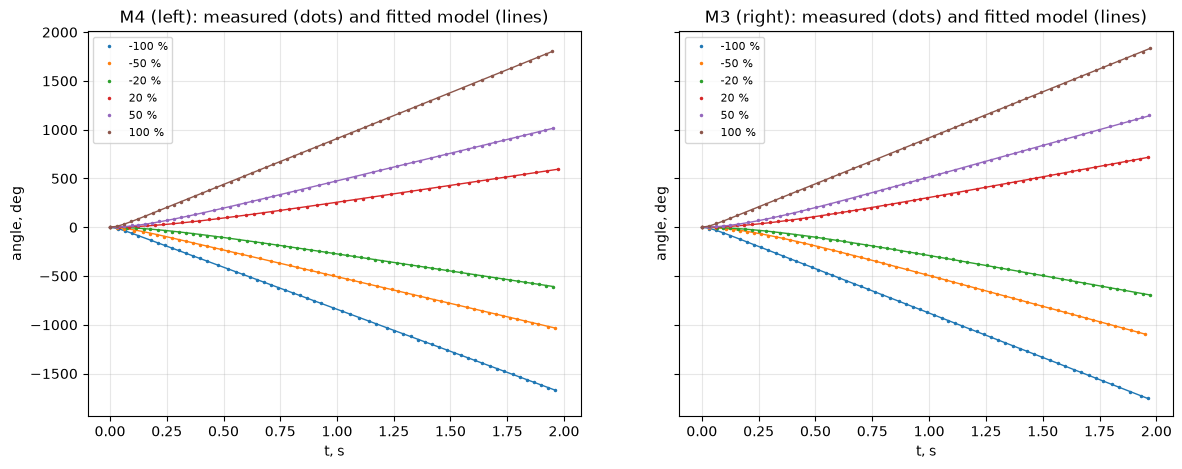

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=100, sharey=True)
for ax, m in zip(axes, MOTORS):            # left panel M4, right panel M3
    for s in split_steps(m):
        if s["level"] in (-100, -50, -20, 20, 50, 100):     # only six levels, or the plot is unreadable
            r = results[m][results[m].pwm == s["level"]].iloc[0]   # fitted w_ss and T_m of this step
            p = ax.plot(s["t"], np.degrees(s["theta"]), ".", ms=3, label=f"{s['level']:.0f} %")   # measured
            ax.plot(s["t"], np.degrees(model(s["t"], r.w_ss, r.T_m)), "-", color=p[0].get_color(), lw=1)   # model
    ax.set_title(f"{m} ({MOTORS[m]}): measured (dots) and fitted model (lines)")
    ax.set_xlabel("t, s"); ax.set_ylabel("angle, deg"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

The fitted curves follow the measured points almost exactly on both wheels; after ~0.2 s every step is a straight line and model and data match. The only differences are at the start: at high PWM the speed-up ($T_m \approx 0.03$ s) is shorter than one sample (~34 ms), and at low PWM friction makes the wheel start later than the ideal model.

## 2. Speed against voltage, $k_e$ and the dead zone

$\omega_{ss}$ against $U$ for both wheels on the same axes. Forward and backward are fitted separately on the
linear part ($|\text{PWM}| \ge 20$ %): $\omega_{ss} = U / k_e + b$, so $k_e$ is 1 / slope. The dead zone
is the largest $|\text{PWM}|$ at which the wheel did not move ($|\omega_{ss}| < 0.3$ rad/s).

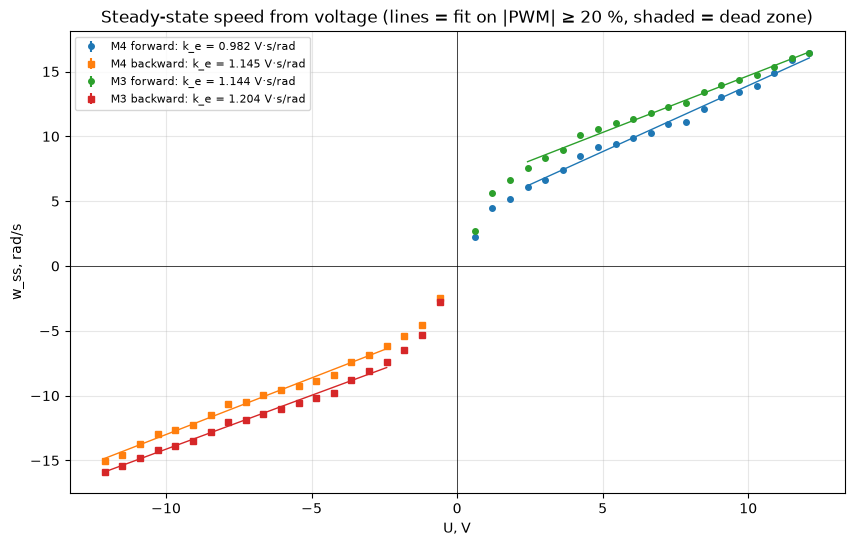

,motor,direction,"k_e, V·s/rad","dead zone, % PWM","mean T_m (|PWM| ≥ 20 %), s","U_battery, V"
0,M4,forward,0.9821,< 5,0.1355,12.1
1,M4,backward,1.1449,< 5,0.1293,12.1
2,M3,forward,1.1436,< 5,0.1724,12.1
3,M3,backward,1.2035,< 5,0.1540,12.1


In [4]:
fits = {}                                  # (motor, direction) -> k_e, dead zone, mean T_m
plt.figure(figsize=(10, 6), dpi=100)
for m in MOTORS:
    r = results[m]
    for sign, name in ((1, "forward"), (-1, "backward")):
        d = r[np.sign(r.pwm) == sign]          # forward (+) or backward (-) levels only
        lin = d[abs(d.pwm) >= LINEAR_FROM]     # the linear part: |PWM| >= 20 %
        slope, b = np.polyfit(lin.U, lin.w_ss, 1)   # straight line w_ss = slope * U + b
        stalled = d[abs(d.w_ss) < 0.3]         # levels where the wheel did not move
        dead = abs(stalled.pwm).max() if len(stalled) else 0
        fits[m, sign] = dict(k_e=1 / slope,    # k_e = 1 / slope because w_ss = U / k_e
                             b=b, dead=dead, min_level=abs(d.pwm).min(),
                             T_m=lin.T_m.mean(), T_m_std=lin.T_m.std())
        p = plt.errorbar(d.U, d.w_ss, yerr=d.w_ss_err, fmt="o" if sign > 0 else "s", ms=4,
                         label=f"{m} {name}: k_e = {1 / slope:.3f} V·s/rad")
        x = np.array([sign * LINEAR_FROM, sign * 100]) / 100 * battery[m]
        plt.plot(x, slope * x + b, "-", color=p[0].get_color(), lw=1)
        if dead:                               # shade the dead zone (none found here)
            plt.axvspan(0, sign * dead / 100 * battery[m], color=p[0].get_color(), alpha=0.15)
plt.axhline(0, color="k", lw=0.5); plt.axvline(0, color="k", lw=0.5)
plt.xlabel("U, V"); plt.ylabel("w_ss, rad/s"); plt.title("Steady-state speed from voltage (lines = fit on |PWM| ≥ 20 %, shaded = dead zone)")
plt.grid(alpha=0.3); plt.legend(fontsize=8); plt.show()

rows = []
for m in MOTORS:
    for sign, name in ((1, "forward"), (-1, "backward")):
        f = fits[m, sign]
        rows.append({"motor": m, "direction": name, "k_e, V·s/rad": round(f["k_e"], 4),
                     "dead zone, % PWM": f"{f['dead']:.0f}" if f["dead"] else f"< {f['min_level']:.0f}",
                     "mean T_m (|PWM| ≥ 20 %), s": round(f["T_m"], 4), "U_battery, V": battery[m]})
display(pd.DataFrame(rows))

Below ~20 % PWM the points rise above the line: already at 5 % both wheels turn at 2.3–2.8 rad/s, so the lines do not pass through zero (offset 3.7–5.9 rad/s) and there is no dead zone down to 5 %. At 90–100 % the points stay slightly above the line, so there is no saturation yet. The right wheel M3 is 11–20 % faster than the left M4 in the middle range (at +50 %: 11.32 vs 9.88 rad/s), but at 100 % forward they are almost equal; M4 is faster forward than backward (16.4 vs 15.1 rad/s at 100 %).

## 3. $T_m$ against PWM

The model assumes $T_m$ does not depend on the voltage. Error bars are the standard error of the fit.

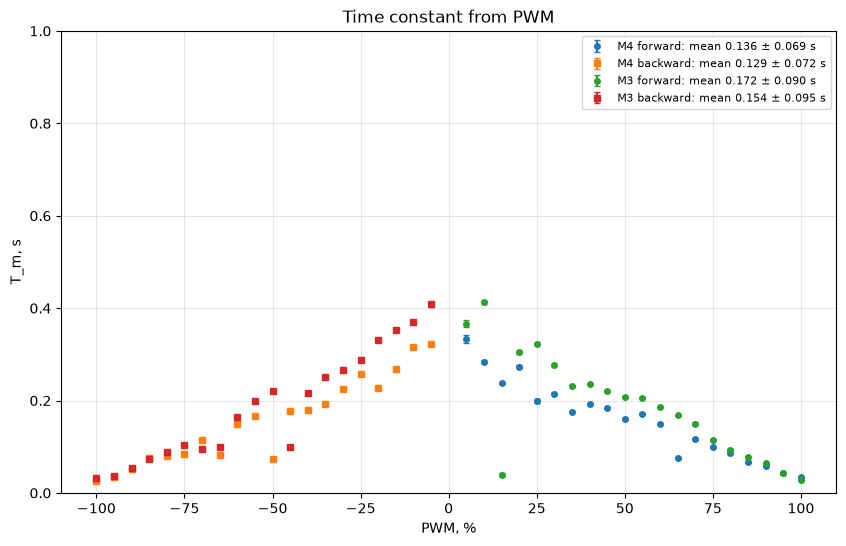

In [5]:
plt.figure(figsize=(10, 6), dpi=100)       # T_m of every step with its fit error
for m in MOTORS:
    r = results[m]
    for sign, name in ((1, "forward"), (-1, "backward")):
        d = r[np.sign(r.pwm) == sign]
        f = fits[m, sign]
        plt.errorbar(d.pwm, d.T_m, yerr=d.T_m_err, fmt="o" if sign > 0 else "s", ms=4, capsize=2,
                     label=f"{m} {name}: mean {f['T_m']:.3f} ± {f['T_m_std']:.3f} s")
plt.ylim(0, 1); plt.xlabel("PWM, %"); plt.ylabel("T_m, s"); plt.title("Time constant from PWM")
plt.grid(alpha=0.3); plt.legend(fontsize=8); plt.show()

$T_m$ is not constant: it falls from ~0.35 s at ±5 % PWM to ~0.03 s at ±100 %, on both wheels and in both directions. At low PWM friction takes a large part of the small torque, so the wheel speeds up slowly. At high PWM the transient is shorter than one sample: the Timer is set to 5 ms, but the real interval is ~34 ms (writing the file takes time), so there are only one or two points to fit.

## 4. One step: measured and simulated

The +50 % step of each wheel, simulated with `odeint` as in the course notebook. The model uses the
parameters **identified from all levels** (the fitted line of section 2, $\omega_{ss} = U/k_e + b$, and the
mean $T_m$ of section 3), not the fit of this step, so this is a real check of the model. The fit of this
single step is drawn for comparison.

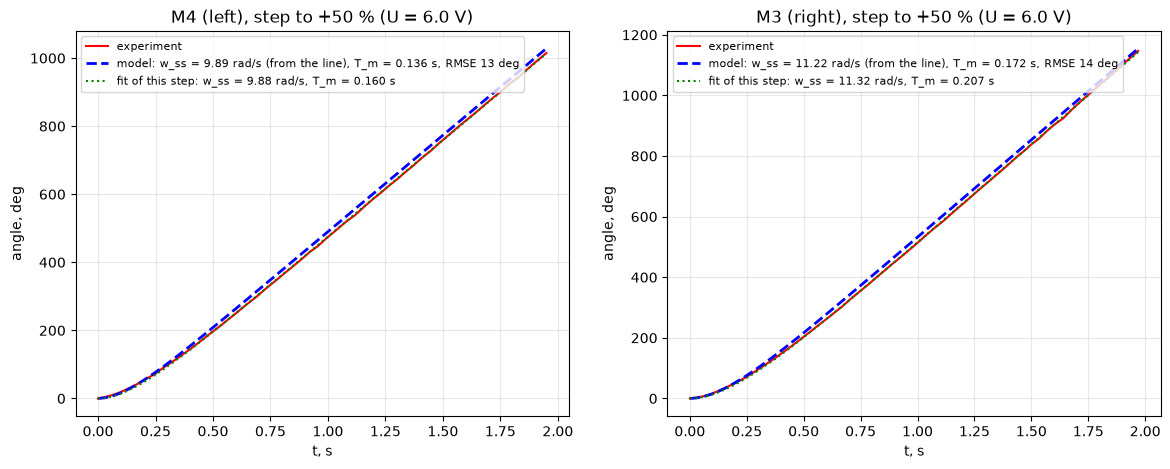

In [6]:
LEVEL = 50                                 # the step to simulate
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=100)
for ax, m in zip(axes, MOTORS):
    s = [q for q in split_steps(m) if q["level"] == LEVEL][0]   # measured +50 % step
    k_e, b, T_m = fits[m, 1]["k_e"], fits[m, 1]["b"], fits[m, 1]["T_m"]   # identified from all levels
    u = LEVEL / 100 * battery[m]
    w_target = u / k_e + b                                        # steady-state speed from the fitted line

    def motor(state, t):
        speed, angle = state
        return np.array([(w_target - speed) / T_m, speed])        # = -speed/T_m + u/(T_m k_e) when b = 0

    y = odeint(motor, [0, 0], s["t"])      # integrate from speed 0, angle 0; y[:,1] = angle
    r = results[m][results[m].pwm == LEVEL].iloc[0]
    rmse = np.degrees(np.sqrt(np.mean((s["theta"] - y[:, 1]) ** 2)))
    ax.plot(s["t"], np.degrees(s["theta"]), "r-", lw=1.5, label="experiment")
    ax.plot(s["t"], np.degrees(y[:, 1]), "b--", lw=2, label=f"model: w_ss = {w_target:.2f} rad/s (from the line), T_m = {T_m:.3f} s, RMSE {rmse:.0f} deg")
    ax.plot(s["t"], np.degrees(model(s["t"], r.w_ss, r.T_m)), "g:", lw=1.5, label=f"fit of this step: w_ss = {r.w_ss:.2f} rad/s, T_m = {r.T_m:.3f} s")
    ax.set_title(f"{m} ({MOTORS[m]}), step to +{LEVEL} % (U = {u:.1f} V)")
    ax.set_xlabel("t, s"); ax.set_ylabel("angle, deg"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

After 2 s the simulated motor is about 15° ahead of the real one for M4 and 13° for M3 (RMSE 13° and 14°, ~1.3 % of the angle). The steady speed from the line matches this step well (9.89 vs 9.88 rad/s, 11.22 vs 11.32 rad/s), so the gap comes from $T_m$: the mean $T_m$ (0.136 / 0.172 s) is shorter than this step's own $T_m$ (0.160 / 0.207 s). So the model reaches full speed too early, gains a few degrees at the start and keeps that lead.

## 5. Checks of the measurement

Zero drift (the encoder with the motor off for 3 s at the start), the real sampling interval, and how far the
wheel coasts after power-off.

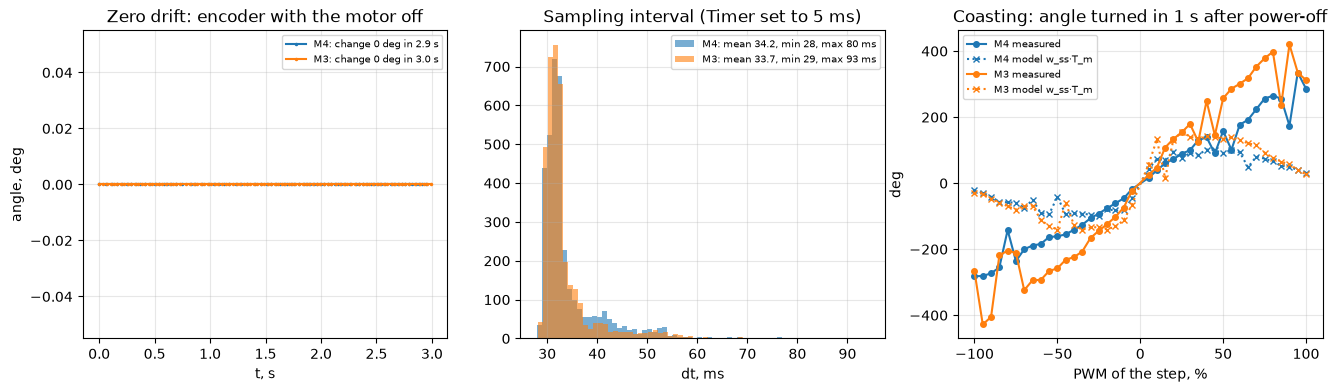

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), dpi=100)
for m in MOTORS:
    angle, t, pwm = load(m)
    n0 = np.argmax(pwm != 0)                                      # first line with the motor on = end of the 3 s zero block
    axes[0].plot((t[:n0] - t[0]) / 1000, angle[:n0] - angle[0], ".-", ms=3,
                 label=f"{m}: change {angle[:n0].max() - angle[:n0].min():.0f} deg in {(t[n0 - 1] - t[0]) / 1000:.1f} s")
    dt = np.diff(t)                                               # sampling interval
    axes[1].hist(dt, bins=np.arange(dt.min() - 0.5, dt.max() + 1.5), alpha=0.6,
                 label=f"{m}: mean {dt.mean():.1f}, min {dt.min():.0f}, max {dt.max():.0f} ms")
    r = results[m]                                                # coasting angle vs the model w_ss * T_m
    p = axes[2].plot(r.pwm, r.coast_deg, "o-", ms=4, label=f"{m} measured")
    axes[2].plot(r.pwm, np.degrees(r.w_ss * r.T_m), "x:", ms=4, color=p[0].get_color(), label=f"{m} model w_ss·T_m")
axes[0].set_title("Zero drift: encoder with the motor off"); axes[0].set_xlabel("t, s"); axes[0].set_ylabel("angle, deg")
axes[1].set_title("Sampling interval (Timer set to 5 ms)"); axes[1].set_xlabel("dt, ms")
axes[2].set_title("Coasting: angle turned in 1 s after power-off"); axes[2].set_xlabel("PWM of the step, %"); axes[2].set_ylabel("deg")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.show()

The first-order model fits each step well, but its parameters change with voltage: $\omega_{ss}(U)$ is linear only above ~20 % PWM, and $T_m$ falls from ~0.35 s at ±5 % to ~0.03 s at ±100 %. The wheels differ: $k_e$ is 0.982 / 1.145 V·s/rad for M4 and 1.144 / 1.204 for M3 (forward / backward), and the right wheel turns 11–20 % faster in the middle range; neither has a dead zone above 5 %. So with the same PWM the robot will curve to the left, and odometry must use each wheel's own encoder, not the commanded PWM.